# Tests de validation MSUC

Ce notebook entraine la politique SDDP sur une instance puis la simule. On choisit l'instance,
l'horizon, le nombre de scenarios, la formulation (3-bin ou intervalle) et les reglages de `train`
(nombre d'iterations, ecart d'optimalite du MIP racine), puis on regarde la trajectoire de la borne
inferieure, le cout de la politique simulee et la repartition du temps de calcul.

Les verifications rigoureuses (borne <= optimum exact <= politique, equivalence des formulations
3-bin et intervalle, Prop. 3) sont dans `examples/toy_convergence.jl` et `examples/compare_formulations.jl`.

A executer depuis la racine du depot (le kernel Julia active automatiquement ce projet).

## 1. Installation des dependances (une seule fois)

Installe les paquets listes dans `Project.toml` (JuMP, Gurobi.jl, CSV, DataFrames, NCDatasets, ...). 
Necessite une licence Gurobi valide sur la machine.

In [1]:
import Pkg
Pkg.activate(@__DIR__)  # active ce projet, quel que soit le kernel Julia choisi
Pkg.instantiate()

  Activating project at `~/Documents/MSUC`


In [2]:
using MSUC, Gurobi, Printf, Random

GRB_ENV = Gurobi.Env()
optimizer = () -> Gurobi.Optimizer(GRB_ENV)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05


#2 (generic function with 1 method)

In [3]:
INSTANCE    = "Data/T-Ramp/50_0_5_w.nc4"  # chemin vers le fichier .nc4
T           = 24                           # horizon (nombre de pas de temps)
S           = 1                            # nombre de scenarios (support de l'innovation ARMA)
SIGMA       = 1.0                          # amplitude de l'alea : multiplie l'ecart-type de l'innovation ARMA (0.0 = deterministe)
ITERATIONS  = 22                          # nombre d'iterations SDDP
MIP_GAP     = 1e-3                         # ecart d'optimalite du MIP racine : 1e-2 = 1 %, 1e-3 = 0.1 %, nothing = defaut du solveur (1e-4)
PASSES_PER_MIP = 1                         # passes avant/arriere (LP) par resolution du MIP racine : 1 = usuel, 5 ou 10 = plus de coupes entre deux MIP ; ITERATIONS compte alors des cycles
PRINT_LEVEL = 1                            # 0 = silencieux, 1 = log complet de MSUC.train

# :threebin  -> formulation 3-bin  (Sect. 2 de l'article, coupes (12))
# :extended  -> formulation intervalle (Sect. 3 de l'article, coupes (41))
METHOD = :extended

:extended

In [4]:
FORMULATIONS = Dict(
    :threebin => (MSUC.subproblem_builder_UC_def,     MSUC.SDDPFormulation,     "3-bin"),
    :extended => (MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation, "intervalle"),
)
builder, method, label = FORMULATIONS[METHOD]

instance = MSUC.parse_nc4(INSTANCE, optimizer, T; S = S, sigma = SIGMA)
@printf("instance %s : %d unites, %d intervalles, T = %d, S = %d, methode = %s\n",
        basename(INSTANCE), instance.N,
        sum(length(u.intervals) for u in instance.Thermalunits), T, S, label)

instance 50_0_5_w.nc4 : 50 unites, 11650 intervalles, T = 24, S = 1, methode = intervalle


In [5]:
model = MSUC.PolicyGraph(
    builder, instance, 1.0, MSUC.Graph(T + 1), method;   # force = 1 : l'amplitude de l'alea est donnee par SIGMA
    lower_bound = 0.0, optimizer = optimizer,
)

Random.seed!(MSUC.SEED)   # meme graine que `train_job` (runSMS.jl) : les runs sont reproductibles
MSUC.train(model; iteration_limit = ITERATIONS, mip_gap = MIP_GAP,
            passes_per_mip = PASSES_PER_MIP, print_level = PRINT_LEVEL)

-------------------------------------------------------------------
         MSUC.jl (c) Oscar Dowson and contributors, 2017-25
-------------------------------------------------------------------
problem
  nodes           : 25
  state variables : 52
  scenarios       : 1.00000e+00
  existing cuts   : false
subproblem structure
  VariableRef                             : [359, 15405]
  AffExpr in MOI.EqualTo{Float64}         : [3, 4973]
  AffExpr in MOI.GreaterThan{Float64}     : [1, 51]
  AffExpr in MOI.LessThan{Float64}        : [200, 4800]
  VariableRef in MOI.EqualTo{Float64}     : [1, 1]
  VariableRef in MOI.GreaterThan{Float64} : [52, 11700]
  VariableRef in MOI.LessThan{Float64}    : [50, 50]
  VariableRef in MOI.Parameter{Float64}   : [250, 250]
  VariableRef in MOI.ZeroOne              : [3650, 3650]
numerical stability report
  matrix range     [1e-01, 8e+03]
  objective range  [1e+00, 4e+03]
  bounds range     [1e+02, 3e+02]
  rhs range        [1e+00, 8e+03]
-----------------

### Resultats : trajectoire de la borne et cout de la politique simulee

it   1   borne = 194403.68   incumbent = 194403.68
it   2   borne = 1865030.70   incumbent = 1866890.54
it   3   borne = 1950555.20   incumbent = 1951067.36
it   4   borne = 4690939.03   incumbent = 4695427.13
it   5   borne = 4741909.50   incumbent = 4746481.43
it   6   borne = 5515602.09   incumbent = 5517274.28
it   7   borne = 9261093.20   incumbent = 9270012.13
it   8   borne = 9294819.85   incumbent = 9300265.35
it   9   borne = 9303587.55   incumbent = 9312857.95
it  10   borne = 9310490.78   incumbent = 9319199.65
it  11   borne = 9315448.55   incumbent = 9324529.40
it  12   borne = 9322874.54   incumbent = 9331745.55
it  13   borne = 9337595.77   incumbent = 9345231.14
it  14   borne = 9339853.35   incumbent = 9343874.44
it  15   borne = 9340761.13   incumbent = 9345482.75
it  16   borne = 9340978.67   incumbent = 9345836.00
it  17   borne = 9354155.61   incumbent = 9363185.74
it  18   borne = 9375277.07   incumbent = 9381528.10
it  19   borne = 9377545.43   incumbent = 938505

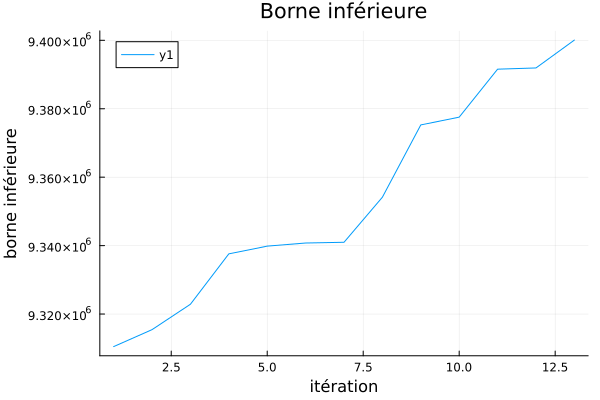

In [12]:
using Plots
log = model.most_recent_training_results.log
for l in log
    @printf("it %3d   borne = %.2f   incumbent = %.2f\n", l.iteration, l.bound, l.incumbent)
end
plot([l.bound for l in log if l.iteration >= 10], title = "Borne inférieure", xlabel = "itération", ylabel = "borne inférieure")

In [7]:
t_sim = @elapsed sim = MSUC.simulate(model; seed = MSUC.SEED)   # meme graine que `simulate_job` (runSMS.jl)
@printf("\ncout de la politique simulee = %.2f  (%d chemins, exhaustif = %s, %.1f s)\n",
        sim.cost, sim.npaths, sim.exhaustive, t_sim)
@printf("intervalle de confiance a 95 %% : [%.2f, %.2f]  (erreur standard %.2f)\n",
        sim.ci95[1], sim.ci95[2], sim.stderr)
@printf("borne finale = %.2f  ->  encadrement relatif = %.2e\n",
        log[end].bound, 100*(sim.cost - log[end].bound) / abs(log[end].bound))


cout de la politique simulee = 10493943.77  (1 chemins, exhaustif = true, 3.5 s)
intervalle de confiance a 95 % : [10493943.77, 10493943.77]  (erreur standard 0.00)
borne finale = 9400070.67  ->  encadrement relatif = 1.16e+01


### Temps de calcul par poste

Chronometres de `train` : racine (MIP), passe avant, passe arriere (resolution des LP, calcul des
coefficients des coupes, ajout des coupes) et mise a jour du planning.

In [13]:
MSUC.TimerOutputs.print_timer(stdout, model.timer_output; compact = true)

─────────────────────────────────────────────────────────────────────
                                          Time          Allocations  
                                    ───────────────   ───────────────
          Total measured:                 186s            3.76GiB    

Section                     ncalls     time    %tot     alloc    %tot
─────────────────────────────────────────────────────────────────────
solve_first_stage_problem       22    24.1s   81.6%    264MiB   11.4%
backward_pass                   22    2.61s    8.9%   1.13GiB   50.2%
  compute_coefficients         528    1.43s    4.8%   0.94GiB   41.7%
  add_cut                      528    605ms    2.1%   97.0MiB    4.2%
  solve_subproblem             528    579ms    2.0%    100MiB    4.3%
    get_dual_solution          528    409ms    1.4%   81.6MiB    3.5%
forward_pass                    22    1.94s    6.6%    710MiB   30.7%
  solve_subproblem             528    1.85s    6.3%    701MiB   30.3%
  sample_scenario  

### Temps du MIP racine par iteration

Le probleme racine est un MIP resolu a chaque iteration : c'est en general le poste dominant de `train`.
Son temps croit avec le nombre de coupes accumulees ; l'option `MIP_GAP` (cellule des parametres) permet de l'accelerer.

MIP racine : 23.1 s au total, soit 78 % du temps d'entrainement (29.6 s)


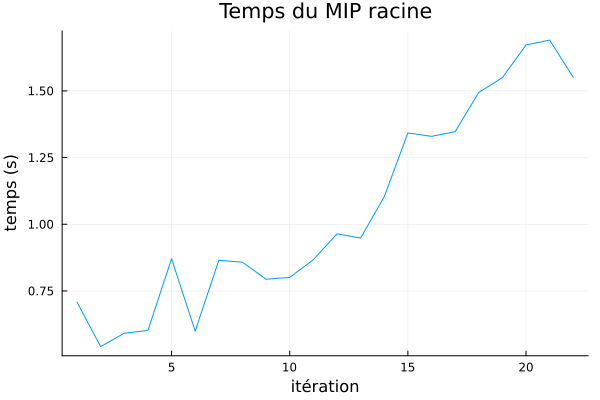

In [14]:
using Plots
t_mip = model[1].computation_time[1:length(log)]   # une resolution du MIP racine par iteration
@printf("MIP racine : %.1f s au total, soit %.0f %% du temps d'entrainement (%.1f s)\n",
        sum(t_mip), 100 * sum(t_mip) / log[end].time, log[end].time)
plot(t_mip, title = "Temps du MIP racine", xlabel = "itération", ylabel = "temps (s)", legend = false)